In [1]:
import cv2 as cv
import numpy as np
import sys

#기본 카메라 지정 가능(0번)
cap=cv.VideoCapture(0,cv.CAP_DSHOW)	# 카메라와 연결 시도

if not cap.isOpened():
    sys.exit('카메라 연결 실패')

frames=[]
while True:
    ret,frame=cap.read()			# 비디오를 구성하는 프레임 획득
    
    if not ret:
        print('프레임 획득에 실패하여 루프를 나갑니다.')
        break
        
    cv.imshow('Video display',frame)
    
    key=cv.waitKey(1)	# 1밀리초 동안 키보드 입력 기다림
    if key==ord('c'):	# 'c' 키가 들어오면 프레임을 리스트에 추가
        frames.append(frame) 
    elif key==ord('q'):	# 'q' 키가 들어오면 루프를 빠져나감
        break 
    
cap.release()			# 카메라와 연결을 끊음
cv.destroyAllWindows() 

if len(frames)>0:		# 수집된 영상이 있으면
    imgs=frames[0]
    for i in range(1,min(3,len(frames))):	# 최대 3개까지 이어 붙임
        imgs=np.hstack((imgs,frames[i]))
    
    cv.imshow('collected images',imgs)
    
    cv.waitKey(0)
    cv.destroyAllWindows()
    cv.waitKey(1)

In [ ]:
import cv2 as cv
import numpy as np
import sys

#기본 카메라 지정 가능(0번)
cap=cv.VideoCapture(0,cv.CAP_DSHOW)	# 카메라와 연결 시도

if not cap.isOpened():
    sys.exit('카메라 연결 실패')

frames=[]
while True:
    ret,frame=cap.read()			# 비디오를 구성하는 프레임 획득
    
    if not ret:
        print('프레임 획득에 실패하여 루프를 나갑니다.')
        break
        
    cv.imshow('Video display',frame)
    
    key=cv.waitKey(1)	# 1밀리초 동안 키보드 입력 기다림
    if key==ord('c'):	# 'c' 키가 들어오면 프레임을 리스트에 추가
        frames.append(frame) 
    elif key==ord('q'):	# 'q' 키가 들어오면 루프를 빠져나감
        break 
    
cap.release()			# 카메라와 연결을 끊음
cv.destroyAllWindows() 

if len(frames)>0:		# 수집된 영상이 있으면
    imgs=frames[0]
    for i in range(1,min(3,len(frames))):	# 최대 3개까지 이어 붙임
        imgs=np.hstack((imgs,frames[i]))
    
    cv.imshow('collected images',imgs)
    
    cv.waitKey()
    cv.destroyAllWindows()

KeyboardInterrupt: 

: 

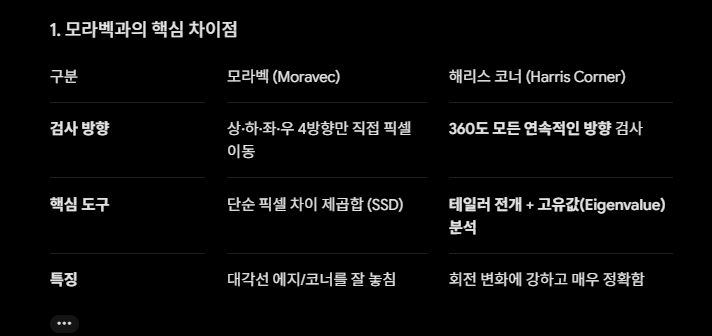

#### 모라벡은 상하좌우로만 값을 뽑는다 -> 너무 인의적이다?
#### 해리스는 360도 모든 각도를 한번 확인해본다.
-> 모든 각도를 계산 한 후에 행렬로 모아서 확인한다

2차 모멘트 행렬 계산 후에 고윳값 계산 결과(람다 값)들이 다 작으면 코너가 아니다.
둘중에 하나만 크다? 그러면 한방향에서 변화가 크다. -> 코너는 아니더라도 엣지는 나올 수 있다
람다 값이 둘다 크게 나오는 경우는 코너일 수 있다.

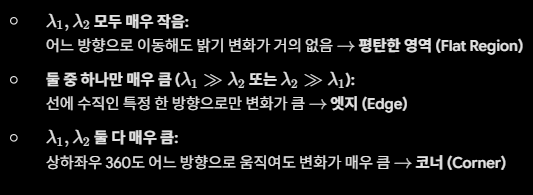

In [ ]:
import cv2 as cv
import numpy as np

img=np.array([[0,0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0,0],
              [0,0,0,1,0,0,0,0,0,0],
              [0,0,0,1,1,0,0,0,0,0],
              [0,0,0,1,1,1,0,0,0,0],
              [0,0,0,1,1,1,1,0,0,0],
              [0,0,0,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0,0]],dtype=np.float32)

ux=np.array([[-1,0,1]])
uy=np.array([-1,0,1]).transpose()
k=cv.getGaussianKernel(3,1)
g=np.outer(k,k.transpose())

dy=cv.filter2D(img,cv.CV_32F,uy)
dx=cv.filter2D(img,cv.CV_32F,ux)
#각각의 부분의 값에 제곱을 해주어서 차이를 더 크게 해준다?
#동시에 발생하는 정도를 확인해주고 싶어서 dyx= dy*dx를 해주는거다.
dyy=dy*dy
dxx=dx*dx
dyx=dy*dx
#그냥 연산 할 수 있는데 가우시안 필터의 경우 원형 대칭 구조를 가지므로, 이미지가 회전해도
#일관된 코너 점수를 얻을 수 있어서 활용한다.
gdyy=cv.filter2D(dyy,cv.CV_32F,g)
gdxx=cv.filter2D(dxx,cv.CV_32F,g)
gdyx=cv.filter2D(dyx,cv.CV_32F,g)
#코너 점수 계산식
C=(gdyy*gdxx-gdyx*gdyx)-0.04*(gdyy+gdxx)*(gdyy+gdxx)

for j in range(1,C.shape[0]-1):		# 비최대 억제
    for i in range(1,C.shape[1]-1):
        if C[j,i]>0.1 and sum(sum(C[j,i]>C[j-1:j+2,i-1:i+2]))==8:
            img[j,i]=9			# 특징점을 원본 영상에 9로 표시
                
np.set_printoptions(precision=2)
print(dy) 
print(dx) 
print(dyy) 
print(dxx) 
print(dyx) 
print(gdyy) 
print(gdxx) 
print(gdyx) 
print(C)					# 특징 가능성 맵 
print(img)					# 특징점을 9로 표시한 원본 영상 

popping=np.zeros([160,160],np.uint8)	# 화소 확인 가능하게 16배로 확대
for j in range(0,160):
    for i in range(0,160):
        popping[j,i]=np.uint8((C[j//16,i//16]+0.06)*700)  

cv.imshow('Image Display2',popping)    
cv.waitKey()
cv.destroyAllWindows()

[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  1. -1. -1.  0.  0.  0.  0.]
 [ 0.  0.  1.  1.  0. -1. -1.  0.  0.  0.]
 [ 0.  0.  1.  1.  0.  0. -1. -1.  0.  0.]
 [ 0.  0.  1.  1.  0.  0.  0. -1. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]]
[[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  0. -1.  0.  0.  0.  0.  0.]
 [ 0.  0.  1.  1. -1. -1.  0.  0.  0.  0.]
 [ 0.  0.  1.  1.  0. -1. -1.  0.  0.  0.]
 [ 0.  0.  1.  1.  0.  0. -1. -1.  0.  0.]
 [ 0.  0.  1.  1.  0.  0.  0. -1. -1.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]]
[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 1. 1. 1. 1. 0. 0. 0. 0.]
 [0. 0

In [14]:
import cv2 as cv
import numpy as np

# 1. 이미지를 반드시 흑백(그레이스케일)으로 읽어옵니다.
img = cv.imread('./building.png', cv.IMREAD_GRAYSCALE)

ux = np.array([[-1, 0, 1]])
uy = np.array([-1, 0, 1]).transpose()
k = cv.getGaussianKernel(3, 1)
g = np.outer(k, k.transpose())

dy = cv.filter2D(img, cv.CV_32F, uy)
dx = cv.filter2D(img, cv.CV_32F, ux)

# 각각의 부분의 값에 제곱을 해주어 차이를 강조하고,
# 동시 발생 정도(대각선/코너 성분)를 파악하기 위해 dyx = dy * dx 수행
dyy = dy * dy
dxx = dx * dx
dyx = dy * dx

# 가우시안 필터로 주변 윈도우 합산 (원형 대칭성으로 회전 불변성 제공)
gdyy = cv.filter2D(dyy, cv.CV_32F, g)
gdxx = cv.filter2D(dxx, cv.CV_32F, g)
gdyx = cv.filter2D(dyx, cv.CV_32F, g)

# 코너 점수 계산식 R
C = (gdyy * gdxx - gdyx * gdyx) - 0.04 * (gdyy + gdxx) * (gdyy + gdxx)

# 비최대 억제 (Non-Maximum Suppression)
for j in range(1, C.shape[0] - 1):
    for i in range(1, C.shape[1] - 1):
        if C[j, i] > 0.1 and sum(sum(C[j, i] > C[j - 1 : j + 2, i - 1 : i + 2])) == 8:
            img[j, i] = 255  # 눈에 잘 띄도록 밝은 흰색(255)으로 표시

np.set_printoptions(precision=2)
print("--- dy --- \n", dy)
print("--- dx --- \n", dx)
print("--- C (Corner Map) --- \n", C)
print("--- Result Image --- \n", img)

# C 반응 지도를 16배 확대하여 시각화 (인덱스 범위 자동 대응)
h, w = C.shape
popping = np.zeros((h * 16, w * 16), np.uint8)
for j in range(0, h * 16):
    for i in range(0, w * 16):
        # 0~255 사이로 잘라내기(clip) 처리로 안전하게 변환
        val = (C[j // 16, i // 16] + 0.06) * 700
        popping[j, i] = np.clip(val, 0, 255)

cv.imshow('Corner Response Map (16x)', popping)
cv.imshow('Detected Corners', img)
cv.waitKey(0)
cv.destroyAllWindows()

--- dy --- 
 [[  0.  -3. -52. ...  -6. -66.   0.]
 [  0.  10. -31. ... -20. -53.   0.]
 [  0.  18. -15. ... -12. -14.   0.]
 ...
 [  0.  21.  28. ...   7.   3.   0.]
 [  0.  13.  11. ...   7.   7.   0.]
 [  0.   0.   7. ...   7.   7.   0.]]
--- dx --- 
 [[  0.  -3. -52. ...  -6. -66.   0.]
 [  0.  10. -31. ... -20. -53.   0.]
 [  0.  18. -15. ... -12. -14.   0.]
 ...
 [  0.  21.  28. ...   7.   3.   0.]
 [  0.  13.  11. ...   7.   7.   0.]
 [  0.   0.   7. ...   7.   7.   0.]]
--- C (Corner Map) --- 
 [[-1.67e+02 -4.09e+04 -2.30e+05 ... -2.19e+05 -4.35e+05 -5.92e+05]
 [-8.95e+02 -2.57e+04 -1.50e+05 ... -1.21e+05 -2.31e+05 -3.05e+05]
 [-3.32e+03 -7.79e+03 -4.32e+04 ... -2.16e+04 -3.51e+04 -4.07e+04]
 ...
 [-2.90e+03 -1.00e+04 -2.65e+04 ... -3.96e+02 -1.98e+02 -7.58e+01]
 [-1.87e+03 -4.44e+03 -8.70e+03 ... -2.31e+02 -1.50e+02 -6.96e+01]
 [-4.13e+02 -6.99e+02 -1.66e+03 ... -2.31e+02 -2.02e+02 -1.15e+02]]
--- Result Image --- 
 [[123 139 120 ... 185 167 119]
 [131 149 141 ... 167 140 114]


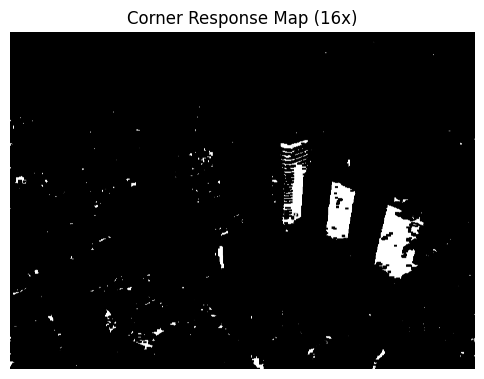

In [15]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지를 흑백(그레이스케일)으로 로드
img = cv.imread('./building.png', cv.IMREAD_GRAYSCALE)

ux = np.array([[-1, 0, 1]])
uy = np.array([-1, 0, 1]).transpose()
k = cv.getGaussianKernel(3, 1)
g = np.outer(k, k.transpose())

dy = cv.filter2D(img, cv.CV_32F, uy)
dx = cv.filter2D(img, cv.CV_32F, ux)

dyy = dy * dy
dxx = dx * dx
dyx = dy * dx

gdyy = cv.filter2D(dyy, cv.CV_32F, g)
gdxx = cv.filter2D(dxx, cv.CV_32F, g)
gdyx = cv.filter2D(dyx, cv.CV_32F, g)

# 코너 점수 계산식 C
C = (gdyy * gdxx - gdyx * gdyx) - 0.04 * (gdyy + gdxx) * (gdyy + gdxx)

# 비최대 억제 (Non-Maximum Suppression)
for j in range(1, C.shape[0] - 1):
    for i in range(1, C.shape[1] - 1):
        if C[j, i] > 0.1 and sum(sum(C[j, i] > C[j - 1 : j + 2, i - 1 : i + 2])) == 8:
            img[j, i] = 255  # 코너 위치를 흰색으로 표시

# 16배 확대 이미지 생성
h, w = C.shape
popping = np.zeros((h * 16, w * 16), np.uint8)
for j in range(0, h * 16):
    for i in range(0, w * 16):
        val = (C[j // 16, i // 16] + 0.06) * 700
        popping[j, i] = np.clip(val, 0, 255)

# Matplotlib으로 아래 출력창에 출력
plt.figure(figsize=(6, 6))
plt.imshow(popping, cmap='gray')
plt.title('Corner Response Map (16x)')
plt.axis('off')  # 축 눈금 숨기기
plt.show()

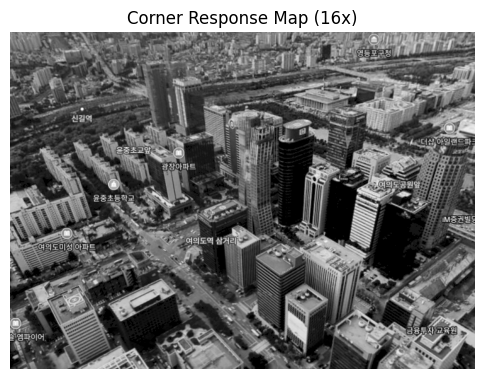

In [17]:
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title('Corner Response Map (16x)')
plt.axis('off')  # 축 눈금 숨기기
plt.show()

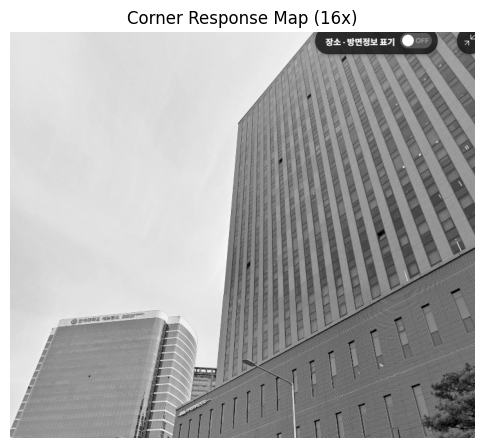

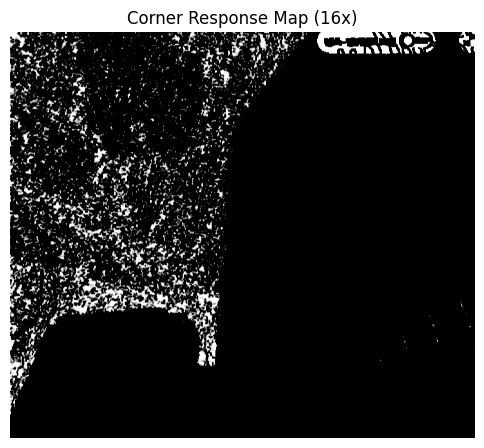

In [24]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지를 흑백(그레이스케일)으로 로드
img = cv.imread('./nbuilding.png', cv.IMREAD_GRAYSCALE)

ux = np.array([[-1, 0, 1]])
uy = np.array([-1, 0, 1]).transpose()
k = cv.getGaussianKernel(3, 1)
g = np.outer(k, k.transpose())

dy = cv.filter2D(img, cv.CV_32F, uy)
dx = cv.filter2D(img, cv.CV_32F, ux)

dyy = dy * dy
dxx = dx * dx
dyx = dy * dx

gdyy = cv.filter2D(dyy, cv.CV_32F, g)
gdxx = cv.filter2D(dxx, cv.CV_32F, g)
gdyx = cv.filter2D(dyx, cv.CV_32F, g)

# 코너 점수 계산식 C
C = (gdyy * gdxx - gdyx * gdyx) - 0.04 * (gdyy + gdxx) * (gdyy + gdxx)

# 비최대 억제 (Non-Maximum Suppression)
for j in range(1, C.shape[0] - 1):
    for i in range(1, C.shape[1] - 1):
        if C[j, i] > C.max() * 0.01 and sum(sum(C[j, i] > C[j - 1 : j + 2, i - 1 : i + 2])) == 8:
            img[j, i] = 255  # 코너 위치를 흰색으로 표시

# 16배 확대 이미지 생성
h, w = C.shape
popping = np.zeros((h * 16, w * 16), np.uint8)
for j in range(0, h * 16):
    for i in range(0, w * 16):
        val = (C[j // 16, i // 16] + 0.06) * 700
        popping[j, i] = np.clip(val, 0, 255)

# Matplotlib으로 아래 출력창에 출력
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.title('Corner Response Map (16x)')
plt.axis('off')  # 축 눈금 숨기기
plt.show()
plt.figure(figsize=(6, 6))
plt.imshow(popping, cmap='gray')
plt.title('Corner Response Map (16x)')
plt.axis('off')  # 축 눈금 숨기기
plt.show()

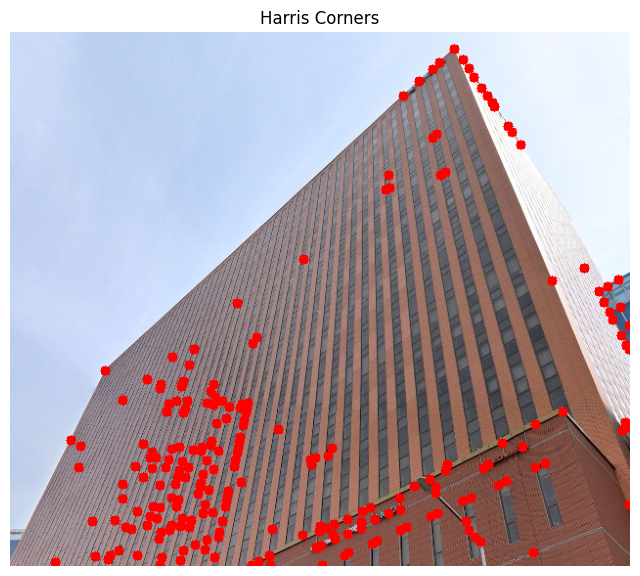

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 로드
img_gray = cv.imread('./building1.png', cv.IMREAD_GRAYSCALE)
img_color = cv.imread('./building1.png')
img_color = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

# 미분 필터 및 가우시안 블러
ux = np.array([[-1, 0, 1]])
uy = np.array([[-1, 0, 1]]).T
k = cv.getGaussianKernel(5, 1.5)
g = np.outer(k, k.T)

dy = cv.filter2D(img_gray, cv.CV_32F, uy)
dx = cv.filter2D(img_gray, cv.CV_32F, ux)

dyy = dy * dy
dxx = dx * dx
dyx = dy * dx

gdyy = cv.filter2D(dyy, cv.CV_32F, g)
gdxx = cv.filter2D(dxx, cv.CV_32F, g)
gdyx = cv.filter2D(dyx, cv.CV_32F, g)

# 코너 반응 점수 C 계산
C = (gdyy * gdxx - gdyx * gdyx) - 0.04 * (gdyy + gdxx)**2

# 2. 비최대 억제(NMS) 및 코너점 검출
# dilate를 사용하여 국소 영역 최대값(Local Maxima)을 빠르게 검출
kernel = np.ones((7, 7), np.uint8)
C_max = cv.dilate(C, kernel)

# 임계값 설정 기존에 0.01에서 0.05로 올렸음
threshold = C.max() * 0.05

#지역 최댓값, 임계값을 넘는 값을 코너로 저장
corners = (C == C_max) & (C > threshold)

# corners의 x값과 y값에 빨간색으로 체크해줌
y_coords, x_coords = np.where(corners)
for y, x in zip(y_coords, x_coords):
    cv.circle(img_color, (x, y), 5, (255, 0, 0), -1)

# 아래 출력창에 출력
plt.figure(figsize=(8, 10))
plt.imshow(img_color)
plt.title('Harris Corners')
plt.axis('off')
plt.show()

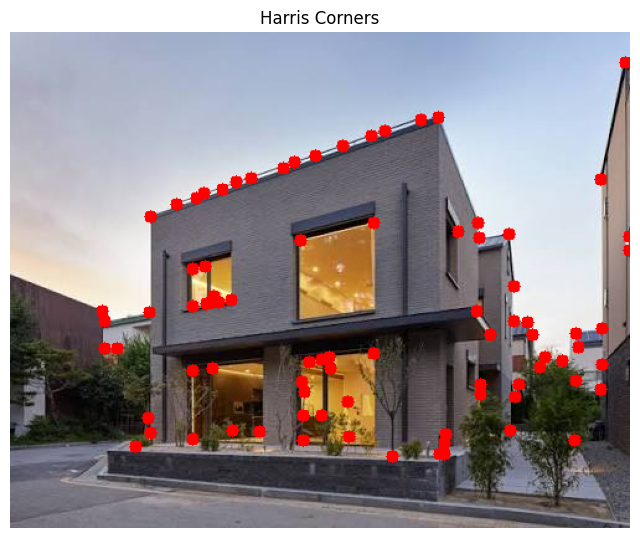

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 이미지 로드
img_gray = cv.imread('./build.jpeg', cv.IMREAD_GRAYSCALE)
img_color = cv.imread('./build.jpeg')
img_color = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)

# 미분 필터 및 가우시안 블러
ux = np.array([[-1, 0, 1]])
# y 미분 위해 x전치
uy = np.array([[-1, 0, 1]]).T
#가우시안 필터 생성 크기5에 표준편차1.5
k = cv.getGaussianKernel(5, 1.5)
#2차원 가우시안 블러커널 생성
g = np.outer(k, k.T)

#이미지에 uy 미분필터 적용한 값
#밝기가 얼마나 급격히 변하는가를 확인하기 위한
dy = cv.filter2D(img_gray, cv.CV_32F, uy)
dx = cv.filter2D(img_gray, cv.CV_32F, ux)

#미분값의 제곱
dyy = dy * dy
dxx = dx * dx
#방향성의 상관관계를 파악하기 위해 필요하다.
dyx = dy * dx

#가우시안 필터를 적용한 값
gdyy = cv.filter2D(dyy, cv.CV_32F, g)
gdxx = cv.filter2D(dxx, cv.CV_32F, g)
gdyx = cv.filter2D(dyx, cv.CV_32F, g)

# 코너 반응 점수 C 계산
C = (gdyy * gdxx - gdyx * gdyx) - 0.04 * (gdyy + gdxx)**2

#7,7 커널 생성
kernel = np.ones((7, 7), np.uint8)
#c에 팽창 연산 적용ㅊ
C_max = cv.dilate(C, kernel)

# 임계값 설정 (상위 명확한 코너만 추출)
threshold = C.max() * 0.05

# NMS 조건: 현재 값이 지역 최대값이고 임계값을 넘는 경우
corners = (C == C_max) & (C > threshold)

# 3. 빨간색 원 그리기
y_coords, x_coords = np.where(corners)
for y, x in zip(y_coords, x_coords):
    cv.circle(img_color, (x, y), 5, (255, 0, 0), -1)

# 4. 결과 출력
plt.figure(figsize=(8, 10))
plt.imshow(img_color)
plt.title('Harris Corners')
plt.axis('off')
plt.show()

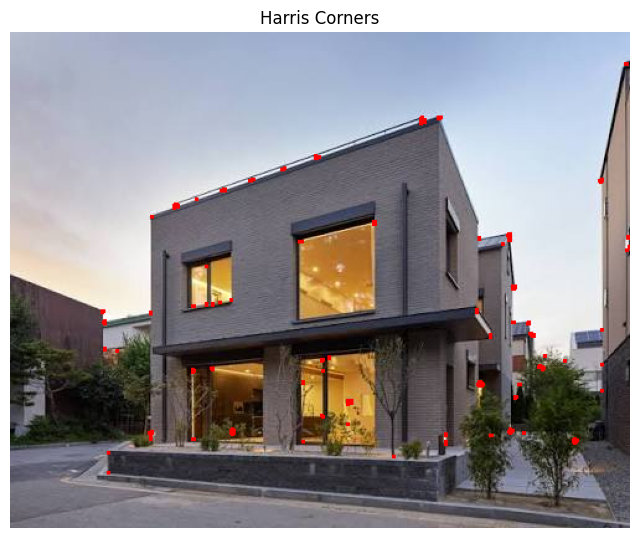

In [33]:
import cv2 as cv
import matplotlib.pyplot as plt

# 이미지 로드
img_color = cv.imread('./build.jpeg')
img_color = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_color, cv.COLOR_RGB2GRAY)

# Harris Corner 검출 (block_size=2, ksize=3, k=0.04)
dst = cv.cornerHarris(img_gray, 2, 3, 0.04)

# 팽창 연산으로 국소 최대점 선별
dst_dilated = cv.dilate(dst, None)

# 임계값 설정 및 코너 표시 (상위 5% 이상값)
threshold = 0.05 * dst.max()
img_color[dst_dilated > threshold] = [255, 0, 0] # 빨간색 적용

# 결과 출력
plt.figure(figsize=(8, 10))
plt.imshow(img_color)
plt.title('Harris Corners')
plt.axis('off')
plt.show()

### SIFT 기술자
#### 그림을 화살표 방향으로 분리해서 각각 히스토그램으로 제작해서 어떠한 경향을 갖는지 출력 -> 블럭 형식으로 나누어서 저장?


In [10]:
import cv2 as cv

img=cv.imread('./ch5/mot_color70.jpg') # 영상 읽기
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create() 
kp,des=sift.detectAndCompute(gray,None)

gray=cv.drawKeypoints(gray,kp,None,flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
cv.imshow('sift', gray)

k=cv.waitKey()
cv.destroyAllWindows()

In [49]:
import cv2 as cv

img=cv.imread('building.png') # 영상 읽기
gray=cv.cvtColor(img,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create() 
kp,des=sift.detectAndCompute(gray,None)

gray=cv.drawKeypoints(gray,kp,None,flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
cv.imshow('sift', gray)

k=cv.waitKey()
cv.destroyAllWindows()

총 키포인트 개수: 4415개
가장 많은 키포인트가 향하는 방향 구간: 0.0도 ~ 10.0도
해당 구간의 키포인트 개수: 341개

--- [방향별 히스토그램 수치] ---
  0° ~  10° : 341개
 10° ~  20° : 156개
 20° ~  30° : 84개
 30° ~  40° : 96개
 40° ~  50° : 79개
 50° ~  60° : 64개
 60° ~  70° : 54개
 70° ~  80° : 70개
 80° ~  90° : 152개
 90° ~ 100° : 217개
100° ~ 110° : 163개
110° ~ 120° : 90개
120° ~ 130° : 56개
130° ~ 140° : 57개
140° ~ 150° : 65개
150° ~ 160° : 68개
160° ~ 170° : 122개
170° ~ 180° : 303개
180° ~ 190° : 281개
190° ~ 200° : 155개
200° ~ 210° : 94개
210° ~ 220° : 102개
220° ~ 230° : 94개
230° ~ 240° : 103개
240° ~ 250° : 68개
250° ~ 260° : 94개
260° ~ 270° : 190개
270° ~ 280° : 233개
280° ~ 290° : 148개
290° ~ 300° : 58개
300° ~ 310° : 75개
310° ~ 320° : 52개
320° ~ 330° : 63개
330° ~ 340° : 73개
340° ~ 350° : 86개
350° ~ 360° : 209개


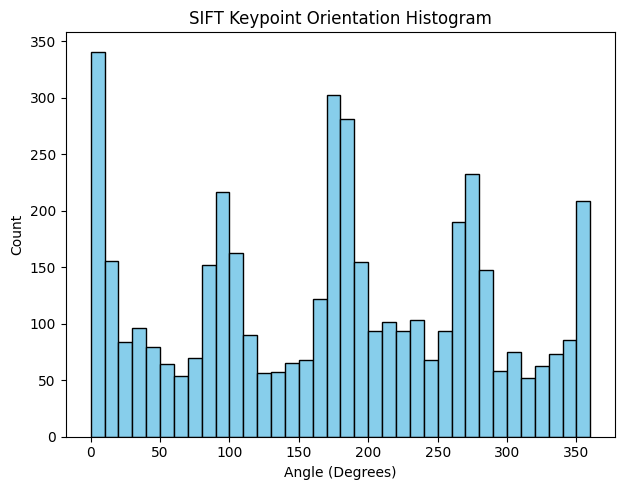

In [46]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. 영상 읽기 및 그레이스케일 변환
img = cv.imread('./ch5/mot_color70.jpg')
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# 2. SIFT 특징점 검출 및 기술자 계산
sift = cv.SIFT_create()
kp, des = sift.detectAndCompute(gray, None)

# 3. 모든 키포인트의 방향(angle, 0~360도) 추출
angles = [p.angle for p in kp]

# 4. 방향 히스토그램 생성 (36개 구간, 각 구간은 10도씩)
counts, bin_edges = np.histogram(angles, bins=36, range=(0, 360))

# 5. 가장 많은 키포인트가 가리키는 방향 찾기
max_index = np.argmax(counts)
most_frequent_angle_range = (bin_edges[max_index], bin_edges[max_index + 1])
max_count = counts[max_index]

print(f"총 키포인트 개수: {len(kp)}개")
print(f"가장 많은 키포인트가 향하는 방향 구간: {most_frequent_angle_range[0]}도 ~ {most_frequent_angle_range[1]}도")
print(f"해당 구간의 키포인트 개수: {max_count}개\n")

# 각 구간(bin)별 수치 데이터 출력
print("--- [방향별 히스토그램 수치] ---")
for i in range(len(counts)):
    print(f"{int(bin_edges[i]):3d}° ~ {int(bin_edges[i+1]):3d}° : {counts[i]}개")

# 6. OpenCV 결과 이미지 출력 (Rich Keypoints)
img_with_kp = cv.drawKeypoints(gray, kp, None, flags=cv.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
cv.imshow('SIFT Keypoints', img_with_kp)

# 7. Matplotlib를 사용한 히스토그램 시각화 (일반 차트 + 극좌표 원형 차트)
plt.figure(figsize=(12, 5))

# (1) 막대그래프 형태로 출력
plt.subplot(1, 2, 1)
plt.hist(angles, bins=36, range=(0, 360), color='skyblue', edgecolor='black')
plt.title('SIFT Keypoint Orientation Histogram')
plt.xlabel('Angle (Degrees)')
plt.ylabel('Count')


plt.tight_layout()
plt.show()

cv.waitKey(0)
cv.destroyAllWindows()

특징점 개수: 804 8306
매칭에 걸린 시간: 0.03441429138183594


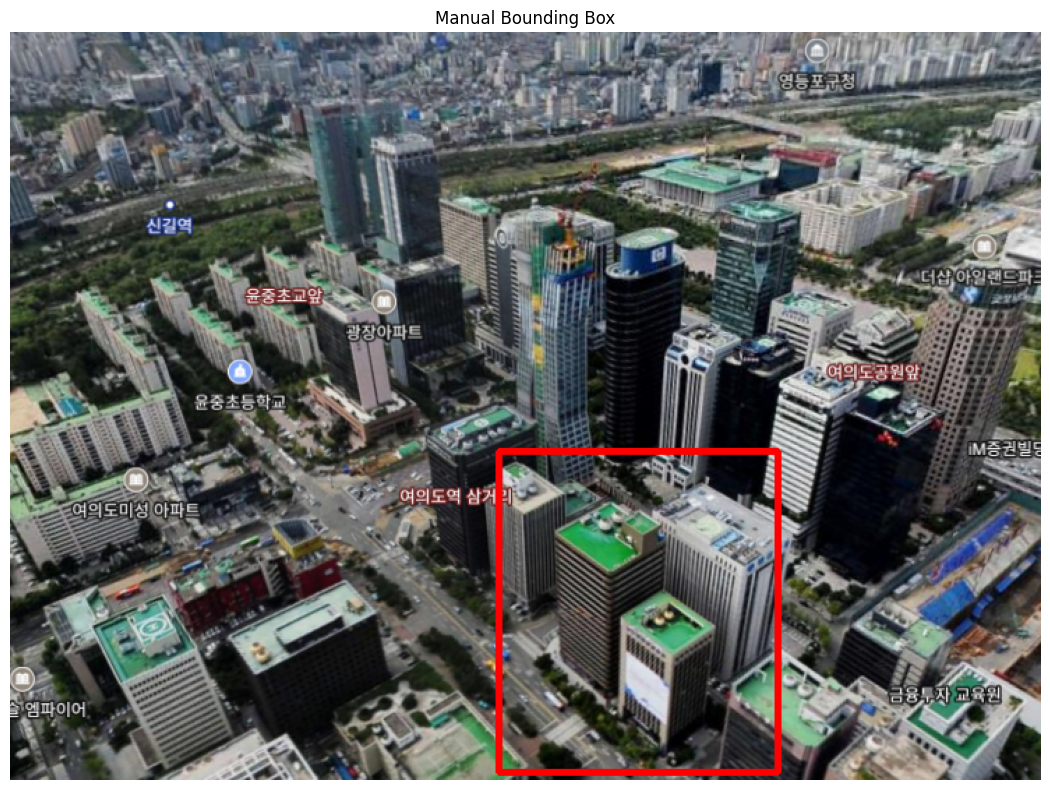

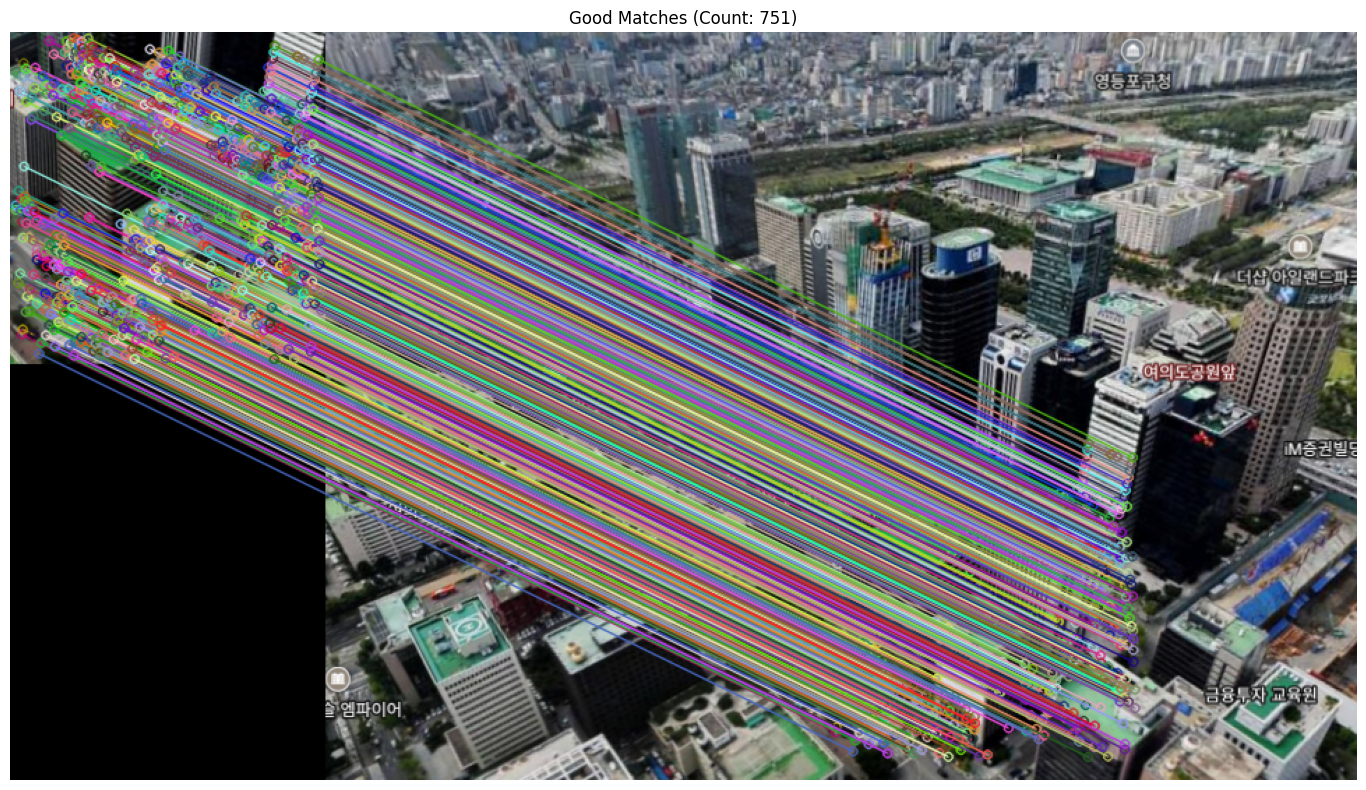

In [ ]:
import cv2 as cv
import numpy as np
import time
import matplotlib.pyplot as plt

img1 = cv.imread('buildingmini.png') # 버스를 크롭하여 모델 영상으로 사용
gray1 = cv.cvtColor(img1, cv.COLOR_BGR2GRAY)
img2 = cv.imread('building.png')     # 장면 영상
gray2 = cv.cvtColor(img2, cv.COLOR_BGR2GRAY)

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)
print('특징점 개수:', len(kp1), len(kp2)) 

start = time.time()
flann_matcher = cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match = flann_matcher.knnMatch(des1, des2, 2)

T = 0.7
good_match = []
for nearest1, nearest2 in knn_match:
    if (nearest1.distance / nearest2.distance) < T:
        good_match.append(nearest1)
print('매칭에 걸린 시간:', time.time() - start) 

img_match = np.empty((max(img1.shape[0], img2.shape[0]), img1.shape[1] + img2.shape[1], 3), dtype=np.uint8)
cv.drawMatches(img1, kp1, img2, kp2, good_match, img_match, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# OpenCV(BGR) -> Matplotlib(RGB) 색상 변환
img_match_rgb = cv.cvtColor(img_match, cv.COLOR_BGR2RGB)
img2_rect = img2.copy()
x, y = 350, 300
w, h = 200, 230
cv.rectangle(img2_rect, (x, y), (x + w, y + h), (0, 0, 255), 4)


img2_rect_rgb = cv.cvtColor(img2_rect, cv.COLOR_BGR2RGB)
plt.figure(figsize=(12, 8))
plt.imshow(img2_rect_rgb)
plt.title('Manual Bounding Box')
plt.axis('off')
plt.tight_layout()
plt.show()

plt.figure(figsize=(15, 8))
plt.imshow(img_match_rgb)
plt.title(f'Good Matches (Count: {len(good_match)})')
plt.axis('off') # 눈금선 제거
plt.tight_layout()
plt.show()

특징점 개수: 167 741
매칭에 걸린 시간: 0.004004955291748047


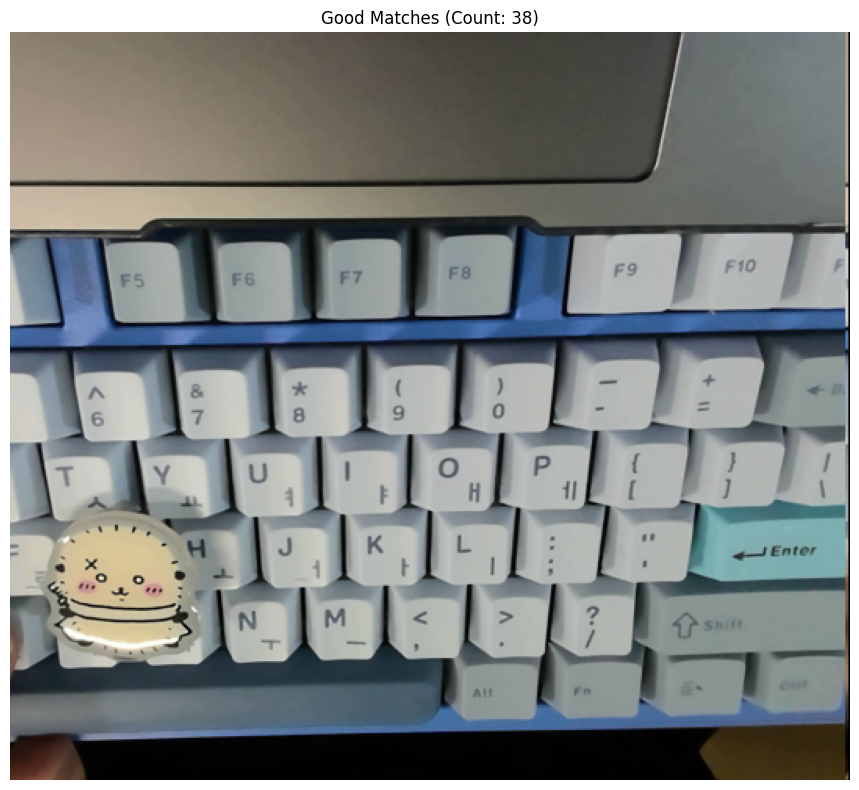

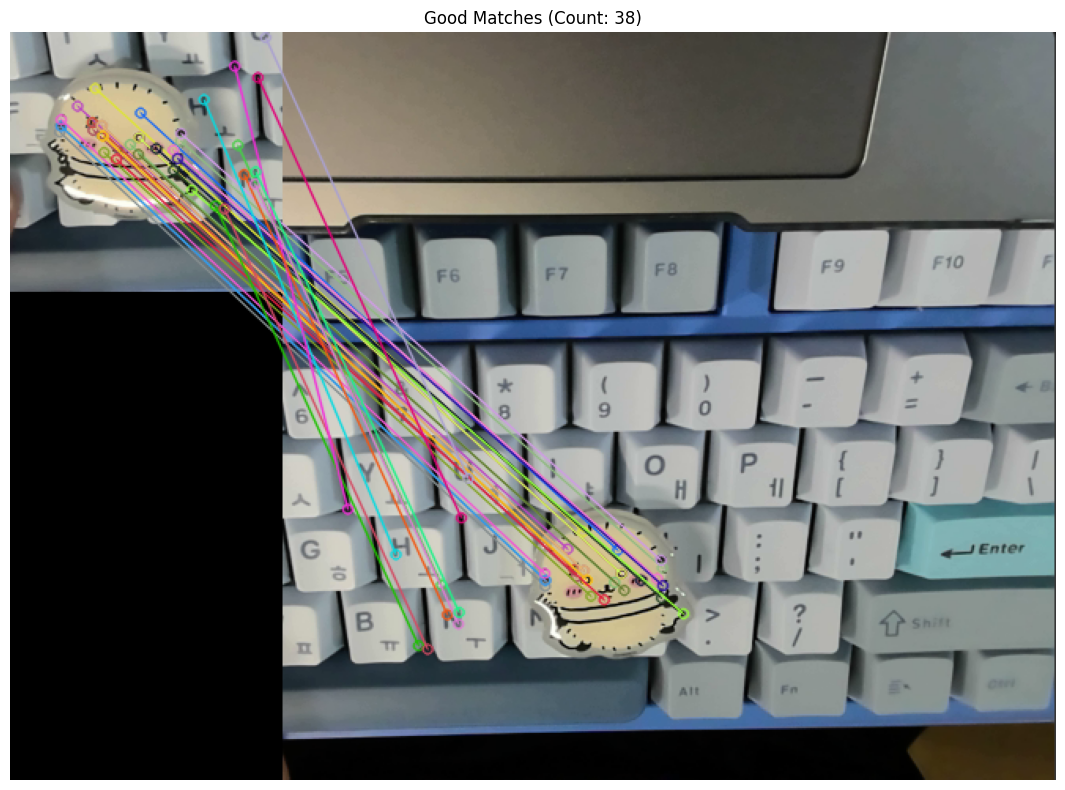

In [ ]:
import cv2 as cv
import numpy as np
import time
import matplotlib.pyplot as plt

img1 = cv.imread('lacko-3.png') # 자리옮긴 랏코 
gray1 = cv.cvtColor(img1, cv.COLOR_BGR2GRAY)
img2 = cv.imread('lacko-1.png')     # 장면 영상
gray2 = cv.cvtColor(img2, cv.COLOR_BGR2GRAY)
img3 = cv.imread('lacko-2.png')

sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)
print('특징점 개수:', len(kp1), len(kp2)) 

start = time.time()
flann_matcher = cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match = flann_matcher.knnMatch(des1, des2, 2)

T = 0.7
good_match = []
for nearest1, nearest2 in knn_match:
    if (nearest1.distance / nearest2.distance) < T:
        good_match.append(nearest1)
print('매칭에 걸린 시간:', time.time() - start) 

img_match = np.empty((max(img1.shape[0], img2.shape[0]), img1.shape[1] + img2.shape[1], 3), dtype=np.uint8)
cv.drawMatches(img1, kp1, img2, kp2, good_match, img_match, flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# OpenCV(BGR) -> Matplotlib(RGB) 색상 변환
img_match_rgb = cv.cvtColor(img_match, cv.COLOR_BGR2RGB)
img3_rgb = cv.cvtColor(img3, cv.COLOR_BGR2RGB)
plt.figure(figsize=(15, 8))
plt.imshow(img3_rgb)
plt.title(f'Good Matches (Count: {len(good_match)})')
plt.axis('off') # 눈금선 제거
plt.tight_layout()
plt.show()
# Matplotlib 시각화 설정
plt.figure(figsize=(15, 8))
plt.imshow(img_match_rgb)
plt.title(f'Good Matches (Count: {len(good_match)})')
plt.axis('off') # 눈금선 제거
plt.tight_layout()
plt.show()

In [50]:
import cv2 as cv
import numpy as np
import time

img1=cv.imread('./ch5/mot_color70.jpg')[190:350,440:560] # 버스를 크롭하여 모델 영상으로 사용
gray1=cv.cvtColor(img1,cv.COLOR_BGR2GRAY)
img2=cv.imread('./ch5/mot_color83.jpg')			     # 장면 영상
gray2=cv.cvtColor(img2,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create()
kp1,des1=sift.detectAndCompute(gray1,None)
kp2,des2=sift.detectAndCompute(gray2,None)
print('특징점 개수:',len(kp1),len(kp2)) 

start=time.time()
flann_matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match=flann_matcher.knnMatch(des1,des2,2)

T=0.7
good_match=[]
for nearest1,nearest2 in knn_match:
    if (nearest1.distance/nearest2.distance)<T:
        good_match.append(nearest1)
print('매칭에 걸린 시간:',time.time()-start) 

img_match=np.empty((max(img1.shape[0],img2.shape[0]),img1.shape[1]+img2.shape[1],3),dtype=np.uint8)
cv.drawMatches(img1,kp1,img2,kp2,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

cv.imshow('Good Matches', img_match)

k=cv.waitKey()
cv.destroyAllWindows()

특징점 개수: 231 4096
매칭에 걸린 시간: 0.01684403419494629


In [44]:
import cv2 as cv
import numpy as np

img1=cv.imread('./ch5/mot_color70.jpg')[190:350,440:560] # 버스를 크롭하여 모델 영상으로 사용
gray1=cv.cvtColor(img1,cv.COLOR_BGR2GRAY)
img2=cv.imread('./ch5/mot_color83.jpg')			     # 장면 영상
gray2=cv.cvtColor(img2,cv.COLOR_BGR2GRAY)

sift=cv.SIFT_create()
#두가지를 동시에 하는 아이들/ 특징점이 어디있는지 찾아서 키포인트에 저장하고, 계산도 해준다.
kp1,des1=sift.detectAndCompute(gray1,None)
kp2,des2=sift.detectAndCompute(gray2,None)

flann_matcher=cv.DescriptorMatcher_create(cv.DescriptorMatcher_FLANNBASED)
knn_match=flann_matcher.knnMatch(des1,des2,2)	# 최근접 2개

T=0.7
good_match=[]
for nearest1,nearest2 in knn_match:
    if (nearest1.distance/nearest2.distance)<T:
        good_match.append(nearest1)

points1=np.float32([kp1[gm.queryIdx].pt for gm in good_match])
points2=np.float32([kp2[gm.trainIdx].pt for gm in good_match])

H,_=cv.findHomography(points1,points2,cv.RANSAC)

h1,w1=img1.shape[0],img1.shape[1] 		# 첫 번째 영상의 크기
h2,w2=img2.shape[0],img2.shape[1] 		# 두 번째 영상의 크기

box1=np.float32([[0,0],[0,h1-1],[w1-1,h1-1],[w1-1,0]]).reshape(4,1,2)
box2=cv.perspectiveTransform(box1,H)

img2=cv.polylines(img2,[np.int32(box2)],True,(0,255,0),8)

img_match=np.empty((max(h1,h2),w1+w2,3),dtype=np.uint8)
cv.drawMatches(img1,kp1,img2,kp2,good_match,img_match,flags=cv.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
   
cv.imshow('Matches and Homography',img_match)

k=cv.waitKey()
cv.destroyAllWindows()